# 09.3 · Embeddings: meaning as a vector, cosine similarity by hand

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/cloudops-one/training-ai-ml/blob/main/modules/09-nlp-genai/03-embeddings/lesson.ipynb)

Read the [README](README.md) first. This notebook checks the toy cosine numbers, downloads a small embedding model, builds a product search over ShopWave's real catalogue, and compares embeddings with TF-IDF for sentiment.

In [1]:
# --- data helper: works locally and on Colab -------------------------------
from pathlib import Path
import urllib.request

def data_path(name):
    """Return a local path to data/<name>, downloading from GitHub on Colab."""
    for parent in [Path.cwd(), *Path.cwd().parents]:
        candidate = parent / "data" / name
        if candidate.exists():
            return candidate
    url = f"https://raw.githubusercontent.com/cloudops-one/training-ai-ml/main/data/{name}"
    dest = Path(name)
    if not dest.exists():
        urllib.request.urlretrieve(url, dest)
    return dest

import os, logging, warnings
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"
os.environ["HF_HUB_VERBOSITY"] = "error"
os.environ["TOKENIZERS_PARALLELISM"] = "false"
logging.getLogger("torch.distributed.elastic.multiprocessing.redirects").setLevel(logging.ERROR)
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import sys
sys.path.insert(0, str(data_path("download.py").parent))

## 1. Cosine similarity by hand

In [2]:
mug, cup, bicycle = np.array([0.9, 0.1, 0.2]), np.array([0.8, 0.2, 0.3]), np.array([0.1, 0.9, 0.1])

def cosine(a, b):
    return a @ b / (np.linalg.norm(a) * np.linalg.norm(b))

print("mug · cup     =", round(mug @ cup, 2), " lengths", round(np.linalg.norm(mug), 3), round(np.linalg.norm(cup), 3))
print("cos(mug, cup)     =", round(cosine(mug, cup), 3))
print("cos(mug, bicycle) =", round(cosine(mug, bicycle), 3))

mug · cup     = 0.8  lengths 0.927 0.877
cos(mug, cup)     = 0.983
cos(mug, bicycle) = 0.237


Normalise first, and cosine similarity becomes a plain dot product:

In [3]:
unit = lambda v: v / np.linalg.norm(v)
print(round(unit(mug) @ unit(cup), 3), round(unit(mug) @ unit(bicycle), 3))

0.983 0.237


## 2. A real embedding model

In [4]:
from sentence_transformers import SentenceTransformer

encoder = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2")   # ~90 MB download, once
print(f"device: {encoder.device}, {sum(p.numel() for p in encoder.parameters()):,} parameters, "
      f"{encoder.get_sentence_embedding_dimension()} numbers per text")

def embed(texts):
    return encoder.encode(list(texts), normalize_embeddings=True, batch_size=64, show_progress_bar=False)

device: mps:0, 22,713,216 parameters, 384 numbers per text


In [5]:
words = ["mug", "cup", "teapot", "bicycle"]
W = embed(words)
pd.DataFrame(W @ W.T, index=words, columns=words).round(3)

,mug,cup,teapot,bicycle
mug,1.000,0.707,0.511,0.212
cup,0.707,1.000,0.427,0.267
teapot,0.511,0.427,1.000,0.098
bicycle,0.212,0.267,0.098,1.000


Same pattern as the toy: *mug* is closest to *cup*, then *teapot*, far from *bicycle*. Each word is now 384 numbers:

In [6]:
print(W.shape, "first 8 numbers of 'mug':", W[0, :8].round(3))

(4, 384) first 8 numbers of 'mug': [-0.061  0.089 -0.022  0.078  0.015  0.011  0.176  0.003]


## 3. Searching ShopWave's real products

In [7]:
from download import load_retail

raw = load_retail()
names = raw["Description"].dropna().str.strip()
counts = names[names.str.len() > 3].value_counts()
not_products = ["POSTAGE", "MANUAL", "DOTCOM POSTAGE", "CARRIAGE", "BANK CHARGES",
                "DISCOUNT", "AMAZON FEE", "SAMPLES", "CRUK COMMISSION"]
# product names are written in capitals; lower-case entries are stock notes ("found", "damaged")
mostly_caps = counts.index.str.count(r"[A-Z]") >= counts.index.str.count(r"[a-z]")
products = counts[(counts >= 5) & mostly_caps & ~counts.index.isin(not_products)].index.to_series(name="name")
products = products.reset_index(drop=True)
print(f"{len(products):,} ShopWave products")
products.sample(8, random_state=1).tolist()

3,524 ShopWave products


['PEARLISED IVORY HEART LARGE',
 'SMALL LICORICE DES PINK BOWL',
 'PINK BERTIE GLASS BEAD BAG CHARM',
 'DROP DIAMANTE EARRINGS GREEN',
 'HAND WARMER OWL DESIGN',
 'NUMBER TILE COTTAGE GARDEN 9',
 'SILVER VANILLA  FLOWER CANDLE POT',
 'SET/3 RED GINGHAM ROSE STORAGE BOX']

In [8]:
E = embed(products.str.lower())

def search(query, k=5):
    scores = E @ embed([query])[0]
    best = scores.argsort()[::-1][:k]
    return [(products.iloc[i], round(float(scores[i]), 3)) for i in best]

print(E.shape)
for query in ["christmas lights", "tea set", "gift for a gardener"]:
    hits = products.str.lower().str.contains(query).sum()
    print(f"\n{query!r}: keyword search finds {hits}")
    for name, score in search(query, 4):
        print(f"   {score:.3f}  {name}")

(3524, 384)

'christmas lights': keyword search finds 3
   0.761  CHRISTMAS LIGHTS 10 SANTAS
   0.749  CHRISTMAS LIGHTS 10 REINDEER
   0.682  CHRISTMAS LIGHTS 10 VINTAGE BAUBLES
   0.653  SET OF 6 T-LIGHTS SANTA

'tea set': keyword search finds 2
   0.663  REGENCY TEA SPOON
   0.662  TEA TIME TEA SET IN GIFT BOX
   0.657  RETRO "TEA FOR ONE"
   0.654  SET OF TEA COFFEE SUGAR TINS PANTRY

'gift for a gardener': keyword search finds 0
   0.565  BOTANICAL LILY GIFT WRAP
   0.529  MINI PAINTED GARDEN DECORATION
   0.502  MAKE YOUR OWN FLOWERPOWER CARD KIT
   0.500  BOTANICAL ROSE GIFT WRAP


Embeddings find related products where keyword search finds two or none. Notice the imperfections: *Regency Tea Spoon* edges out the actual tea set, and the gardener gets botanical gift wrap. Similar topic, not necessarily what the customer wanted.

## 4. A picture of the catalogue

PCA (06.6) squeezes the 384 numbers into 2 for a picture. Products are coloured by a keyword in their name, which the model never saw.

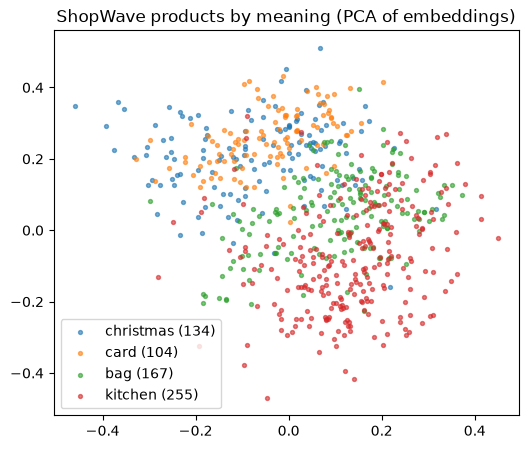

In [9]:
from sklearn.decomposition import PCA

groups = {"christmas": "CHRISTMAS", "card": "CARD", "bag": "BAG", "kitchen": "MUG|CUP|TEA|CAKE"}
label = pd.Series("other", index=products.index)
for g, pattern in reversed(list(groups.items())):
    label[products.str.contains(pattern)] = g
xy = PCA(n_components=2, random_state=0).fit_transform(E)
plt.figure(figsize=(6, 5))
for g in groups:
    m = (label == g).to_numpy()
    plt.scatter(xy[m, 0], xy[m, 1], s=8, alpha=.6, label=f"{g} ({m.sum()})")
plt.legend(); plt.title("ShopWave products by meaning (PCA of embeddings)"); plt.show()

Each group forms its own region. The model was never told what a Christmas product is.

## 5. Embeddings as features for sentiment

In [10]:
from download import load_reviews
from sklearn.model_selection import train_test_split

reviews = load_reviews()          # first run downloads one 117 MB file, then cached
train, test = train_test_split(reviews, test_size=0.2, random_state=42, stratify=reviews["label"])
print(f"{len(reviews):,} reviews ({reviews['label'].mean():.0%} positive): "
      f"train {len(train):,} / test {len(test):,}")
reviews[["text", "label"]].head()

10,000 reviews (50% positive): train 8,000 / test 2,000


,text,label
0,"Great Book, Must read! Ramon found the fabulou...",1
1,A leaker! This is the second generation of the...,0
2,Not For the Professional Cook. Henckels are we...,0
3,Arg! I'd like to see Robert Jordan put to the ...,0
4,"If I could give this minus 5 stars, I'd give i...",0


In [11]:
import time
start = time.time()
E_train, E_test = embed(train["text"]), embed(test["text"])
print(f"encoded {len(train) + len(test):,} reviews in {time.time() - start:.0f} s, shape {E_train.shape}")

encoded 10,000 reviews in 8 s, shape (8000, 384)


In [12]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import accuracy_score

rows = []
for n in [100, 500, 2000, 8000]:
    emb = LogisticRegression(max_iter=2000).fit(E_train[:n], train["label"].iloc[:n])
    tfidf = make_pipeline(TfidfVectorizer(ngram_range=(1, 2), min_df=2), LogisticRegression(max_iter=1000))
    tfidf.fit(train["text"].iloc[:n], train["label"].iloc[:n])
    rows.append({"training reviews": n,
                 "embeddings": accuracy_score(test["label"], emb.predict(E_test)),
                 "TF-IDF": accuracy_score(test["label"], tfidf.predict(test["text"]))})
pd.DataFrame(rows).set_index("training reviews").map("{:.1%}".format)

,embeddings,TF-IDF
training reviews,,
100,74.9%,63.8%
500,81.7%,78.0%
2000,84.5%,84.4%
8000,86.1%,88.4%


With 100 labelled reviews, embeddings win by about 11 points: the model already knows *awful* means *terrible*. With 8,000, TF-IDF learns sentiment-specific words and pulls ahead.

In [13]:
emb_model = LogisticRegression(max_iter=2000).fit(E_train, train["label"])
for review in ["This is not good.", "Not bad at all, I'm pleasantly surprised.",
               "Oh great, another charger that died after a week. Just what I needed."]:
    print(f"P(positive) = {emb_model.predict_proba(embed([review]))[0, 1]:.3f}   {review}")

P(positive) = 0.005   This is not good.
P(positive) = 0.261   Not bad at all, I'm pleasantly surprised.
P(positive) = 0.478   Oh great, another charger that died after a week. Just what I needed.


Negation is still hard for an embedding plus a straight line. 09.6 fine-tunes the whole network instead.

## Quiz answers

1. Nothing on its own. Only distances and directions between whole vectors carry meaning.
2. Then cosine similarity is just a dot product, so comparing a query with every document is one fast matrix multiplication.
3. TF-IDF treats every word as its own unrelated column; the embedding model learned from huge amounts of text that *mug* and *cup* appear in similar contexts.
4. With 100 reviews, TF-IDF has seen too few words to learn their votes, while embeddings bring knowledge learned elsewhere. With 8,000, TF-IDF has enough data to learn precise votes for sentiment words, which a general-purpose embedding blurs together with topic.
5. Any of: similar is not the same as relevant (tea spoon vs tea set), it misses shop-specific words, it cannot do exact matches like product codes, and its results are hard to explain.

**Next:** [09.4 Attention and the Transformer](../04-attention-transformers/)